# Are houses becoming less affordable?
**EDA homework — Edwin**

Question: compared to what people earn, are homes getting harder to buy?

**Data sources**
- OECD, *Analytical house price indicators* — price-to-income ratio (house price index ÷ disposable income per head, 2015 = 100), annual, 1990–2025: https://data-explorer.oecd.org/vis?df[ag]=OECD.ECO.MPD&df[id]=DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES
- 国土交通省 (MLIT), 不動産価格指数（住宅）, 2010 average = 100: https://www.mlit.go.jp/report/press/totikensangyo05_hh_000066.html
  - Nov 2020 values: https://www.mlit.go.jp/common/001388366.pdf
  - Dec 2025 values: https://japanpropertyresearch.com/ja/property-price-index
  - Sep 2025 Minami-Kanto values: https://www.haseko.co.jp/hri/cri/focus/focus-570/index.html

**How to read the ratio:** 100 = the 2015 relationship between house prices and income in that country. 130 means homes cost 30% more *relative to income* than in 2015. It compares a country with its own past — not countries with each other.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import requests, io

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ebeae4", "grid.linewidth": 0.8,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
BLUE, ORANGE, AQUA, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#b5b3ab", "#0b0b0b"
NAMES = {"JPN": "Japan", "KOR": "Korea", "CAN": "Canada", "USA": "United States",
         "AUS": "Australia", "NZL": "New Zealand", "GBR": "United Kingdom", "DEU": "Germany"}

## 1. Load the OECD data
Tries the live OECD API first; if offline, uses the saved copy in `data/`.

In [2]:
URL = ("https://sdmx.oecd.org/public/rest/data/OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES,1.0/"
       + "+".join(NAMES) + ".A.HPI_YDH.IX?startPeriod=1990&dimensionAtObservation=AllDimensions&format=csv")
try:
    r = requests.get(URL, timeout=30); r.raise_for_status()
    live = pd.read_csv(io.StringIO(r.text))
    df = (live.rename(columns={"REF_AREA": "country", "TIME_PERIOD": "year", "OBS_VALUE": "price_to_income_2015_100"})
              [["country", "year", "price_to_income_2015_100"]])
    df["year"] = df["year"].astype(int)
    df.to_csv("data/oecd_price_to_income.csv", index=False)
    print("Loaded LIVE from OECD")
except Exception as e:
    df = pd.read_csv("data/oecd_price_to_income.csv")
    print("Offline -> using saved CSV (", type(e).__name__, ")")

wide = df.pivot(index="year", columns="country", values="price_to_income_2015_100").rename(columns=NAMES)
wide.tail()

Offline -> using saved CSV ( ProxyError )


country,Australia,Canada,Germany,United Kingdom,Japan,Korea,New Zealand,United States
year,,,,,,,,
2021,112.291795,134.418633,130.894528,113.051782,107.247187,95.503029,136.131655,115.788975
2022,115.935389,145.535355,128.577443,118.358032,112.800534,92.096066,130.169585,131.499878
2023,117.259314,137.962546,111.466296,110.993193,115.169319,81.118619,113.842171,126.712218
2024,120.128920,136.173905,104.961338,105.436439,113.872942,76.906538,109.006283,127.228088
2025,119.858274,130.695980,105.359887,103.859772,114.161144,74.397737,103.267832,126.279181


In [3]:
wide.describe().round(1)

country,Australia,Canada,Germany,United Kingdom,Japan,Korea,New Zealand,United States
count,36.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0
mean,87.6,92.8,112.0,90.4,120.5,132.1,84.3,110.6
std,18.9,24.6,13.8,20.5,24.8,60.5,23.5,11.0
min,60.6,65.1,93.8,53.9,96.0,74.4,50.6,90.3
25%,66.6,72.9,99.8,71.1,100.2,99.0,62.4,104.8
50%,88.6,87.9,109.6,98.6,112.3,115.8,83.9,107.5
75%,100.5,113.1,125.4,106.2,136.6,126.3,104.6,116.0
max,120.1,145.5,133.4,118.4,181.9,345.5,136.1,131.5


## 2. First question: are homes less affordable than 10 years ago?
Compare 2025 with 2015 (=100).

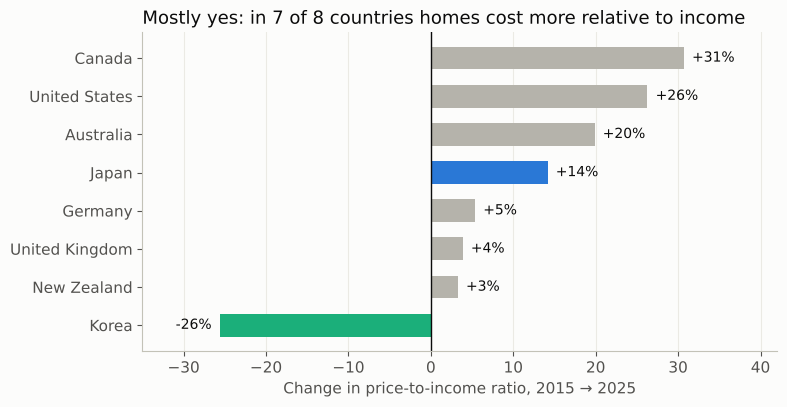

In [4]:
chg = (wide.loc[2025] - 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [BLUE if c == "Japan" else (AQUA if v < 0 else GRAY) for c, v in chg.items()]
ax.barh(chg.index, chg.values, color=colors, height=0.6)
ax.axvline(0, color=INK, lw=1)
for i, v in enumerate(chg.values):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=10, color=INK)
ax.set_xlabel("Change in price-to-income ratio, 2015 → 2025")
ax.set_title("Mostly yes: in 7 of 8 countries homes cost more relative to income", loc="left", fontsize=13, color=INK)
ax.grid(axis="y", visible=False); ax.set_xlim(-35, 42)
plt.tight_layout(); plt.savefig("charts/fig1_change_since_2015.png", dpi=180); plt.show()

**First impression:** yes — Canada (+31%), the US (+26%), Australia (+20%) and Japan (+14%) all got less affordable. Korea is the only exception (−26%).

But 10 years is short. What happens if I look further back?

## 3. Second question: what about the long run (1990–2025)?

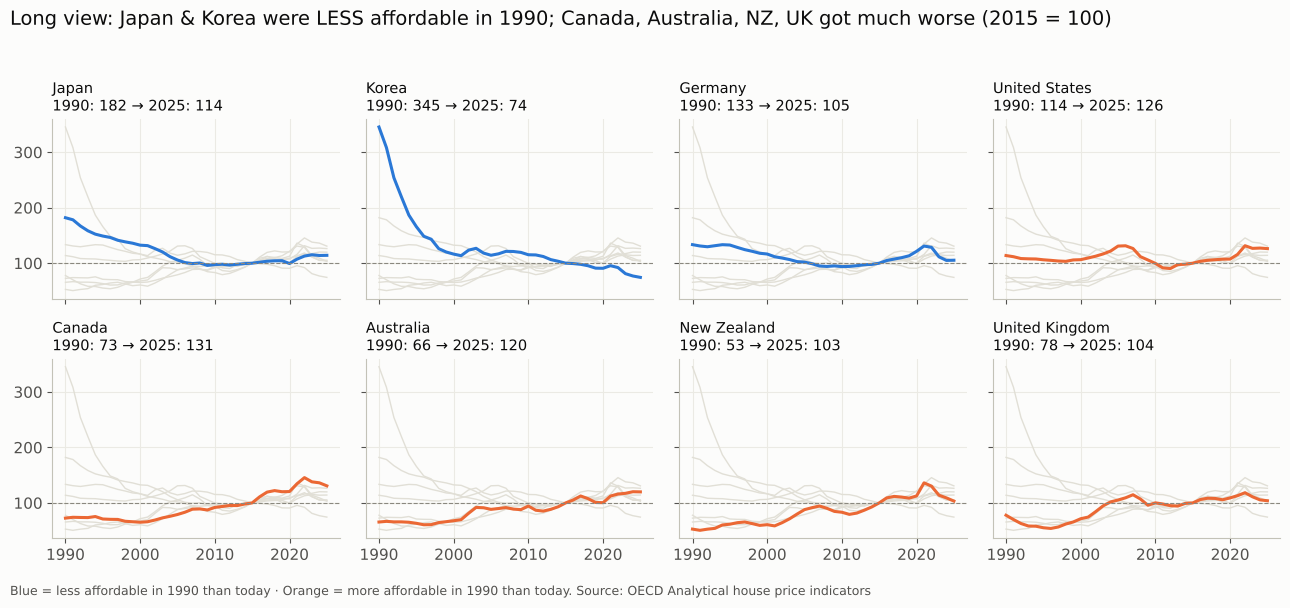

In [5]:
order = ["Japan", "Korea", "Germany", "United States", "Canada", "Australia", "New Zealand", "United Kingdom"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, order):
    for o in order:
        ax.plot(wide.index, wide[o], color="#e1dfd6", lw=1)
    col = BLUE if c in ("Japan", "Korea", "Germany") else ORANGE
    ax.plot(wide.index, wide[c], color=col, lw=2.2)
    ax.axhline(100, color="#8a887f", lw=0.8, ls="--")
    first, last = wide[c].iloc[0], wide[c].iloc[-1]
    ax.set_title(f"{c}\n1990: {first:.0f} → 2025: {last:.0f}", loc="left", fontsize=10.5, color=INK)
fig.suptitle("Long view: Japan & Korea were LESS affordable in 1990; Canada, Australia, NZ, UK got much worse (2015 = 100)",
             x=0.01, ha="left", fontsize=14, color=INK)
fig.text(0.01, 0.005, "Blue = less affordable in 1990 than today · Orange = more affordable in 1990 than today. Source: OECD Analytical house price indicators",
         fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0.03, 1, 0.95)); plt.savefig("charts/fig2_long_view.png", dpi=180); plt.show()

In [6]:
long = pd.DataFrame({"1990": wide.loc[1990], "2025": wide.loc[2025]})
long["change_%"] = ((long["2025"] / long["1990"] - 1) * 100).round(0)
long.sort_values("change_%").round(1)

,1990,2025,change_%
country,,,
Korea,345.5,74.4,-78.0
Japan,181.9,114.2,-37.0
Germany,133.4,105.4,-21.0
United States,113.8,126.3,11.0
United Kingdom,77.7,103.9,34.0
Canada,72.5,130.7,80.0
Australia,65.5,119.9,83.0
New Zealand,52.7,103.3,96.0


**Surprise #1:** Japan was *far* less affordable in 1990 (182) than today (114) — the bubble economy. Korea fell from 345 to 74. Meanwhile Canada, Australia, New Zealand and the UK roughly doubled.

So "houses are getting less affordable" is true for the English-speaking countries, but Japan is **37% more affordable than in 1990**.

That sounded too good. Is it true for every kind of home in Japan?

## 4. Third question: inside Japan, which homes?
MLIT splits prices into residential land, detached houses and condos (マンション). Base: 2010 average = 100.

In [7]:
jp = pd.read_csv("data/mlit_japan_price_index.csv")
jp

,region,period,series_type,residential_land,detached_house,condo,all_residential,source
0,Japan (national),2010 avg,base,100.0,100.0,100.0,100.0,MLIT base year (2010 average = 100)
1,Japan (national),2020-11,seasonally adjusted,100.4,102.1,155.6,115.7,https://www.mlit.go.jp/common/001388366.pdf
2,Japan (national),2025-12,original series,118.3,120.5,221.2,145.1,https://japanpropertyresearch.com/ja/property-...
3,Minami-Kanto (Tokyo area),2025-09,original series,135.6,123.2,218.1,158.5,https://www.haseko.co.jp/hri/cri/focus/focus-5...


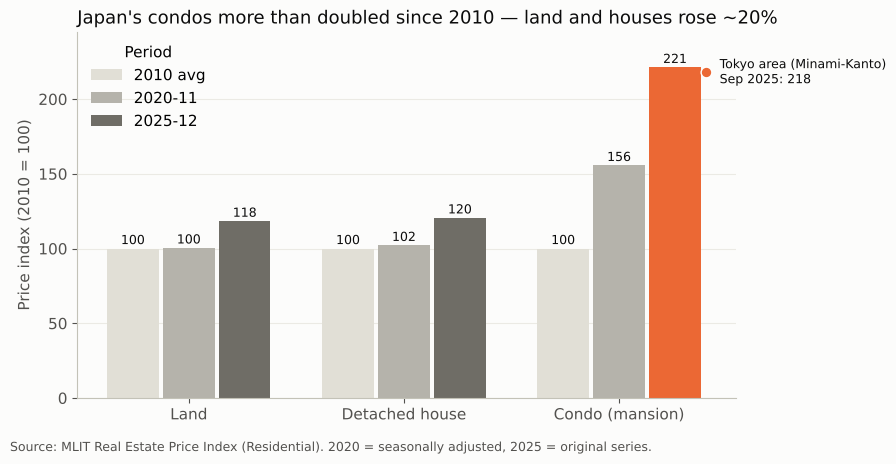

In [8]:
nat = jp[jp["region"] == "Japan (national)"].set_index("period")
tokyo = jp[jp["region"].str.startswith("Minami")].iloc[0]
types = [("residential_land", "Land"), ("detached_house", "Detached house"), ("condo", "Condo (mansion)")]

fig, ax = plt.subplots(figsize=(9, 4.6))
x = range(len(types)); w = 0.26
for k, (per, shade) in enumerate([("2010 avg", "#e1dfd6"), ("2020-11", "#b5b3ab"), ("2025-12", None)]):
    vals = [nat.loc[per, t] for t, _ in types]
    cols = [shade] * 3 if shade else ["#6f6d66", "#6f6d66", ORANGE]
    bars = ax.bar([i + (k - 1) * w for i in x], vals, w * 0.92, color=cols)
    bars[0].set_label(per)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 3, f"{v:.0f}", ha="center", fontsize=9, color=INK)
ax.scatter([2 + 1.55 * w], [tokyo["condo"]], s=60, color=ORANGE, edgecolor="white", zorder=5)
ax.annotate(f"Tokyo area (Minami-Kanto)\nSep 2025: {tokyo['condo']:.0f}", (2 + 1.55 * w, tokyo["condo"]),
            xytext=(10, -8), textcoords="offset points", fontsize=9, color=INK)
ax.set_xticks(list(x)); ax.set_xticklabels([n for _, n in types])
ax.set_ylabel("Price index (2010 = 100)"); ax.set_ylim(0, 245)
ax.legend(title="Period", frameon=False, loc="upper left")
ax.set_title("Japan's condos more than doubled since 2010 — land and houses rose ~20%", loc="left", fontsize=13, color=INK)
ax.grid(axis="x", visible=False)
fig.text(0.01, 0.005, "Source: MLIT Real Estate Price Index (Residential). 2020 = seasonally adjusted, 2025 = original series.", fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig("charts/fig3_japan_types.png", dpi=180); plt.show()

In [9]:
ratio = nat.loc["2025-12", "condo"] / nat.loc["2025-12", "detached_house"]
print(f"Since 2010, condo prices grew {nat.loc['2025-12','condo']-100:.0f}% vs detached houses {nat.loc['2025-12','detached_house']-100:.0f}%")
print(f"Condo index is {ratio:.1f}x the detached-house index")

Since 2010, condo prices grew 121% vs detached houses 20%
Condo index is 1.8x the detached-house index


**Surprise #2:** Japan's national average hides a split. Condos are up **121%** since 2010, detached houses only **20%**. Condos are the homes young city workers buy (near stations, in Tokyo/Osaka), so for them affordability *did* get much worse.

## 5. What I learned
1. **First chart:** "Yes, homes are less affordable" — 7 of 8 countries got worse since 2015.
2. **Longer view changed it:** Japan and Korea are *more* affordable than in 1990. The "affordability crisis" is mainly Canada, Australia, NZ, the UK and the US.
3. **Zooming into Japan changed it again:** the average is calm, but condos doubled. Affordability depends on *what* and *where* you buy.

**Limits:** the OECD ratio is an index (each country vs its own 2015), so it can't say Japan is cheaper than Canada in absolute terms. MLIT values are a few published snapshots, not a full series; income growth in Japan since 2010 was small, so the condo price rise is mostly a real affordability loss.

## 6. Export data for the scrolling web page (`index.html`)

In [10]:
import json
story = {
    "years": wide.index.tolist(),
    "countries": {c: [round(v, 1) for v in wide[c].tolist()] for c in order},
    "japan_types": {p: {t: float(nat.loc[p, t]) for t, _ in types} for p in nat.index},
    "tokyo_condo_2025_09": float(tokyo["condo"]),
}
json.dump(story, open("data/story_data.json", "w"), ensure_ascii=False, indent=1)
print("saved data/story_data.json")

saved data/story_data.json
